# Jets: log p, 2×2 design: higher orders on/off × scalar on/off (5 seeds each)

| arm | label | higher orders (Scat3 Re+Im, Scat4 Mod2 Re+Im) | Scalar_morlet_gaussianK | lam (xseed, t >= 0.99) |
|---|---|---|---|---|
| full | `jets_full` | yes | yes | 1e-2 |
| noscalar | `jets_noscalar` | yes | no | 1e-2 |
| scat2_scalar | `jets_scat2_scalar` | no | yes | 1e-3 |
| scat2 | `jets_scat2` | no | no | 1e-4 |

All arms: L_6 + Scattering 1st + 2nd order, 5 seeds (500-504), same SDE set-up (`jets/launch_jet_SDE.sh`).
**Test:** statistics that only orders 3-4 can carry (time asymmetry: skewness, leverage; cross-scale C_pq; Scat4)
should be lost in `scat2*`. If they are, the higher-order potentials are what produces them.

Data from `python jets/logp_jets.py` (Jean Zay) -> `figures/logp_jets_scat2/logp_jets.npz` (4 arms); this notebook only reads it
(seconds; runs locally too after pulling that one file). Run from `jets/`.

- Theta = Theta_reg(t = 1) at the cross-seed lambda of each arm (table above, window t >= 0.99), unconstrained.
- log p(x) = sum over families of C_F(x) = Theta_F . phi_F(x), **up to the unknown constant -log Z** of each seed:
  only differences under the same Theta are exact (spreads across signals, held-out - training).
- Decomposition by family: share of the variance of log p across signals, Cov(C_F, log p) / Var(log p). Sums to 1;
  a share > 1 or < 0 means families that partly cancel each other.
- **noscalar caveat:** L_6 filter 1 > 0 in 5/5 seeds at lambda 1e-2 (density not normalizable along that direction).

In [10]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from IPython.display import display
import logp_jets as lj
pd.set_option('display.float_format', '{:,.3g}'.format, 'display.width', 220)

runs = lj.load(lj.HERE / 'figures' / 'logp_jets_scat2' / 'logp_jets.npz')   # 4-arm run
for a, r in runs.items():
    print(f"{a}: seeds {r['seeds']}, lam {r['lam']:g}, families {r['families'][:-1]}, "
          f"signals train {r['C']['train'].shape[2]}, held-out {r['C']['heldout'].shape[2]}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
jets_full: seeds [np.int64(500), np.int64(501), np.int64(502), np.int64(503), np.int64(504)], lam 0.01, families [np.str_('L_6'), np.str_('S_morlet'), np.str_('Scat1'), np.str_('Scat2'), np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')], signals train 10000, held-out 6652
jets_noscalar: seeds [np.int64(500), np.int64(501), np.int64(502), np.int64(503), np.int64(504)], lam 0.01, families [np.str_('L_6'), np.str_('Scat1'), np.str_('Scat2'), np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')], signals train 10000, held-out 6652
jets_scat2: seeds [np.int64(500), np.int64(501), np.int64(502), np.int64(503), np.int64(504)], lam 0.0001, families [np.str_('L_6'), np.str_('Scat1'), np.str_('Scat2')], signals train 10000, held-out 6652
jets_scat2_scalar: seeds [np.int64(500), np.int64(501), np.int64(502), np.int64(50

## 1. Distribution of log p (training data)
Each seed centred on its own median (removes its -log Z). Left panels: the 5 seeds of an arm; right: all arms
pooled over seeds.

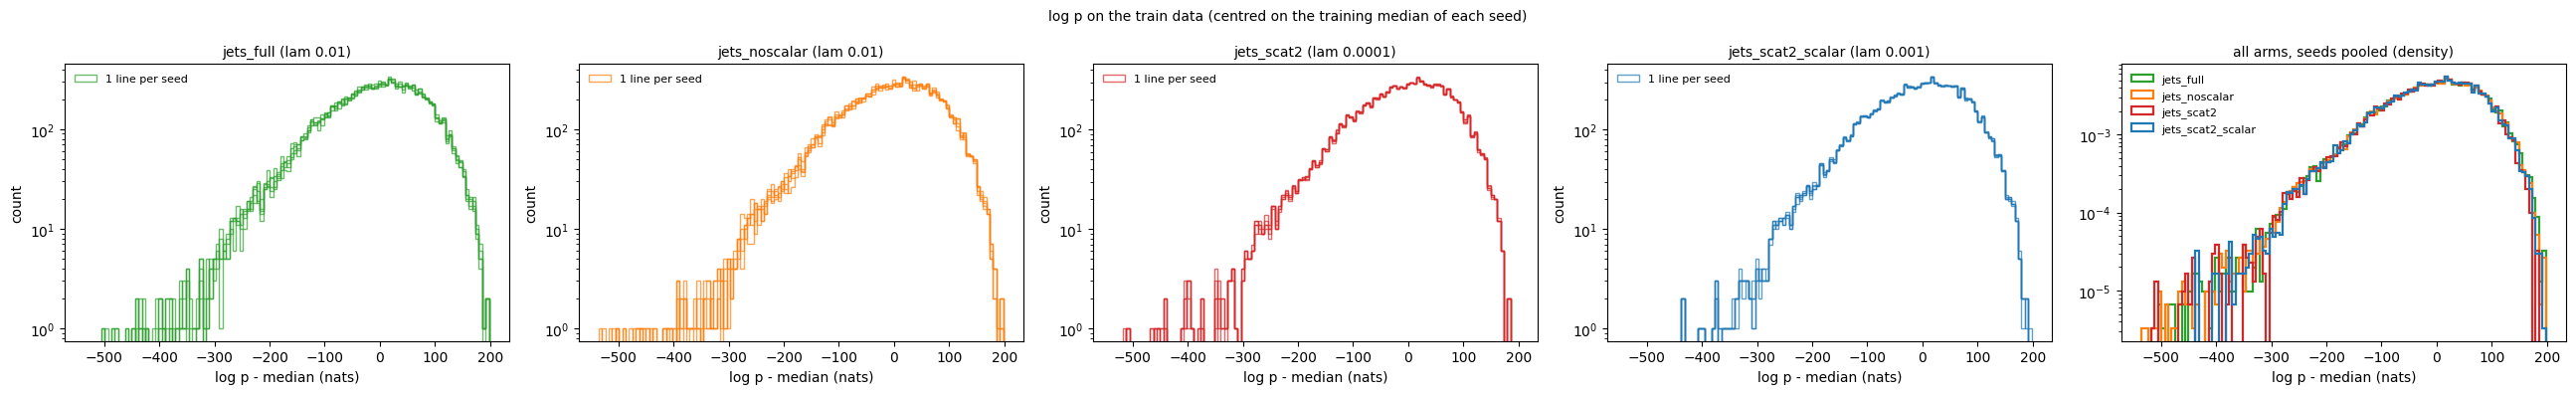

backend: inline


In [11]:
lj.show(lj.plot_distribution(runs))
import matplotlib; print('backend:', matplotlib.get_backend())

In [12]:
# shape numbers per arm, mean (sd) over seeds
from scipy import stats
rows = []
for a, r in runs.items():
    v = [r['C']['train'][i, -1] for i in range(len(r['seeds']))]
    for name, fn in (('std', np.std), ('skew', stats.skew), ('excess kurtosis', stats.kurtosis),
                     ('median - q0.001', lambda x: np.median(x) - np.quantile(x, 1e-3)),
                     ('q0.999 - median', lambda x: np.quantile(x, 0.999) - np.median(x))):
        vals = [fn(x) for x in v]
        rows.append(dict(arm=a, stat=name, mean=np.mean(vals), sd_over_seeds=np.std(vals, ddof=1)))
display(pd.DataFrame(rows).pivot(index='stat', columns='arm'))

mean                                            sd_over_seeds                                           
arm             jets_full jets_noscalar jets_scat2 jets_scat2_scalar     jets_full jets_noscalar jets_scat2 jets_scat2_scalar
stat                                                                                                                         
excess kurtosis      2.26          1.44          1             0.873         0.218        0.0925    0.00887            0.0199
median - q0.001       386           388        398               357          7.63          2.06       1.65             0.866
q0.999 - median       178           174        166               173         0.345          1.13      0.179             0.105
skew               -0.786        -0.751     -0.736            -0.668        0.0162        0.0109    0.00183           0.00199
std                  87.2          86.8       84.6              84.6         0.258         0.278      0.049            0.0179

## 2. log p per potential family, 4 arms (families missing in an arm are left empty)
C_F(x) = Theta_F . phi_F(x), the contribution of family F to log p of signal x. Error bars = sd over the 5 seeds.
1. **mean C_F** (shaded): level only, its zero depends on where phi_F is centred (a constant in phi_F changes it, not p).
2. **std of C_F across signals** (nats): how much F makes one signal more or less likely than another. TOTAL = std of log p.
   Invariant to constants in phi_F and to -log Z: the main panel.
3. **std of C_F / std of log p** (hatched), same arm: puts arms on one scale. > 1 = F alone would spread log p more
   than it is actually spread, i.e. cancelled by other families. Does not sum to 1 (stds don't add).

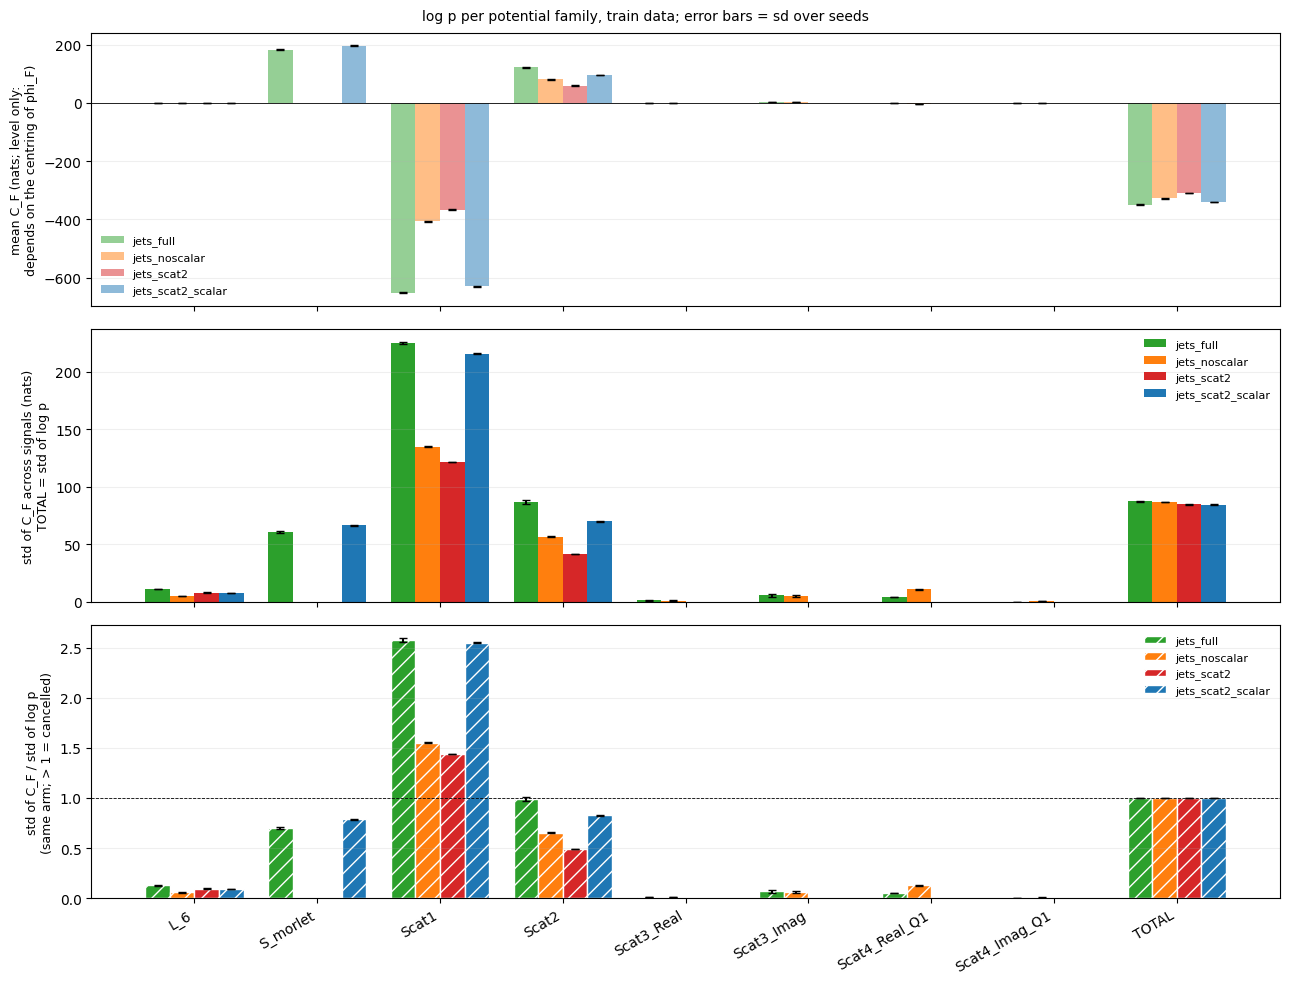

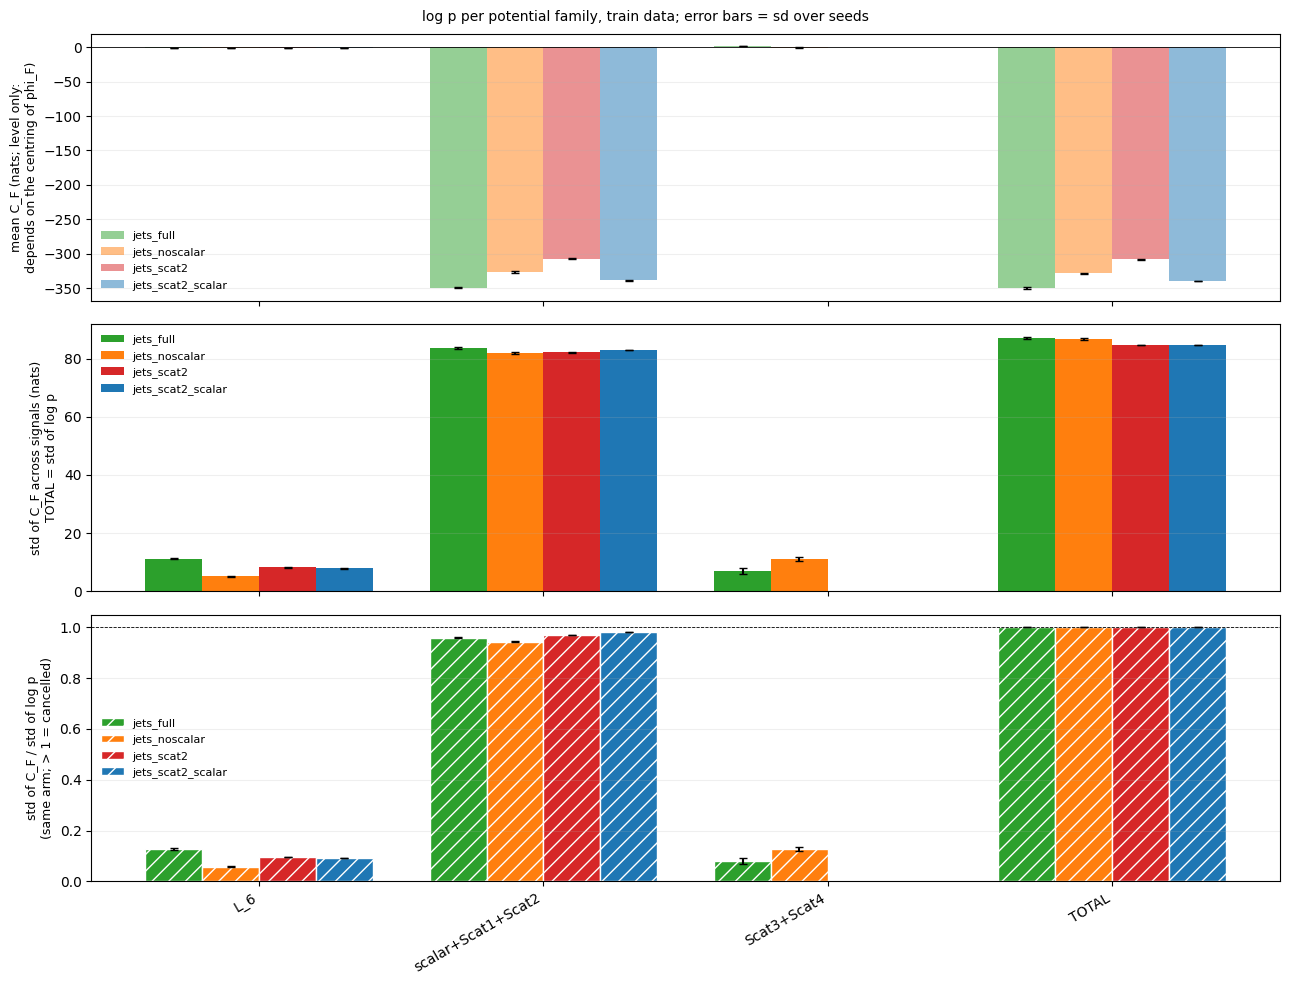

std_signals                                            std_signals_sd                                             std_norm                                           
arm                  jets_full jets_noscalar jets_scat2 jets_scat2_scalar      jets_full jets_noscalar jets_scat2 jets_scat2_scalar jets_full jets_noscalar jets_scat2 jets_scat2_scalar
family                                                                                                                                                                                  
L_6                       11.2          5.07       8.14               7.8          0.253         0.276     0.0725             0.113     0.128        0.0584     0.0962            0.0922
scalar+Scat1+Scat2        83.7          81.8       82.2              83.1          0.306         0.364     0.0299            0.0367      0.96         0.943      0.971             0.983
Scat3+Scat4               6.87          11.1        NaN               NaN           1.07         0.606        NaN               NaN    0.0788         0.127        NaN               NaN
TOTAL                     87.2          86.8       84.6              84.6          0.258         0.278      0.049            0.0179         1             1          1                 1

In [13]:
fig, T = lj.plot_family_bars(runs); lj.show(fig)
# same, families summed into groups per signal (edit the prefixes to regroup; every family in exactly one group)
GROUPS = {'L_6': ('L_6',), 'scalar+Scat1+Scat2': ('S_', 'Scat1', 'Scat2'), 'Scat3+Scat4': ('Scat3', 'Scat4')}
fig, Tg = lj.plot_family_bars(runs, groups=GROUPS); lj.show(fig)
display(Tg.pivot(index='family', columns='arm', values=['std_signals', 'std_signals_sd', 'std_norm'])
          .reindex(list(dict.fromkeys(Tg.family))))

In [14]:
# seed robustness (point a): rel_sd = sd over seeds / |mean|
T['rel_sd_share'] = T['var_share_sd'] / T['var_share'].abs()
display(T.pivot(index='family', columns='arm', values=['var_share', 'var_share_sd', 'rel_sd_share', 'corr',
                                                       'std_signals'])
         .reindex(list(dict.fromkeys(T.family))))

var_share                                            var_share_sd                                            rel_sd_share                                                 corr                           \
arm           jets_full jets_noscalar jets_scat2 jets_scat2_scalar    jets_full jets_noscalar jets_scat2 jets_scat2_scalar    jets_full jets_noscalar jets_scat2 jets_scat2_scalar jets_full jets_noscalar jets_scat2   
family                                                                                                                                                                                                                  
L_6              0.0457        0.0213     0.0331            0.0212     0.000753       0.00234   0.000558          0.000438       0.0165          0.11     0.0169            0.0207     0.357         0.365      0.344   
S_morlet         -0.672           NaN        NaN            -0.782       0.0111           NaN        NaN           0.00501       0.0165           NaN        NaN           0.00641    -0.962           NaN        NaN   
Scat1              2.54          1.54       1.43              2.53       0.0177       0.00379    0.00163           0.00421      0.00696       0.00246    0.00114           0.00167     0.985          0.99      0.994   
Scat2            -0.919        -0.606     -0.461            -0.765        0.019         0.005    0.00199           0.00484       0.0207       0.00825    0.00432           0.00633    -0.925        -0.931     -0.936   
Scat3_Real     -0.00105      -0.00112        NaN               NaN     9.08e-05      9.02e-05        NaN               NaN       0.0862        0.0803        NaN               NaN   -0.0721       -0.0805        NaN   
Scat3_Imag      -0.0085       -0.0115        NaN               NaN      0.00283        0.0019        NaN               NaN        0.332         0.166        NaN               NaN    -0.138        -0.204        NaN   
Scat4_Real_Q1    0.0182        0.0614        NaN               NaN      0.00377        0.0055        NaN               NaN        0.207        0.0897        NaN               NaN     0.355          0.48        NaN   
Scat4_Imag_Q1 -0.000591     -0.000957        NaN               NaN      3.3e-05      0.000117        NaN               NaN       0.0559         0.122        NaN               NaN     -0.16        -0.151        NaN   
TOTAL                 1             1          1                 1            0             0          0                 0            0             0          0                 0         1             1          1   

                                std_signals                                             
arm           jets_scat2_scalar   jets_full jets_noscalar jets_scat2 jets_scat2_scalar  
family                                                                                  
L_6                        0.23        11.2          5.07       8.14               7.8  
S_morlet                 -0.991        60.9           NaN        NaN              66.7  
Scat1                     0.991         225           135        121               215  
Scat2                    -0.925        86.6          56.5       41.6                70  
Scat3_Real                  NaN        1.28          1.22        NaN               NaN  
Scat3_Imag                  NaN        5.81             5        NaN               NaN  
Scat4_Real_Q1               NaN        4.47          11.1        NaN               NaN  
Scat4_Imag_Q1               NaN       0.322          0.55        NaN               NaN  
TOTAL                         1        87.2          86.8       84.6              84.6

In [15]:
# families that cancel: correlation of C_F between families across signals (seed 0 of each arm)
for a, r in runs.items():
    C = r['C']['train'][0, :-1]
    display(pd.DataFrame(np.corrcoef(C), index=r['families'][:-1], columns=r['families'][:-1])
            .style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format('{:.2f}')
            .set_caption(f'{a}, seed {r["seeds"][0]}: corr(C_F, C_G) across signals'))

,L_6,S_morlet,Scat1,Scat2,Scat3_Real,Scat3_Imag,Scat4_Real_Q1,Scat4_Imag_Q1
L_6,1.00,-0.21,0.28,-0.40,-0.03,-0.18,0.73,-0.71
S_morlet,-0.21,1.00,-0.97,0.87,0.10,0.22,-0.31,0.07
Scat1,0.28,-0.97,1.00,-0.96,-0.10,-0.28,0.44,-0.11
Scat2,-0.40,0.87,-0.96,1.00,0.10,0.31,-0.59,0.16
Scat3_Real,-0.03,0.10,-0.10,0.10,1.00,-0.04,-0.06,0.06
Scat3_Imag,-0.18,0.22,-0.28,0.31,-0.04,1.00,-0.24,0.07
Scat4_Real_Q1,0.73,-0.31,0.44,-0.59,-0.06,-0.24,1.00,-0.43
Scat4_Imag_Q1,-0.71,0.07,-0.11,0.16,0.06,0.07,-0.43,1.00


,L_6,Scat1,Scat2,Scat3_Real,Scat3_Imag,Scat4_Real_Q1,Scat4_Imag_Q1
L_6,1.00,0.31,-0.40,-0.02,-0.22,0.64,-0.68
Scat1,0.31,1.00,-0.96,-0.09,-0.28,0.51,-0.10
Scat2,-0.40,-0.96,1.00,0.10,0.29,-0.66,0.14
Scat3_Real,-0.02,-0.09,0.10,1.00,-0.02,-0.08,0.05
Scat3_Imag,-0.22,-0.28,0.29,-0.02,1.00,-0.19,0.04
Scat4_Real_Q1,0.64,0.51,-0.66,-0.08,-0.19,1.00,-0.46
Scat4_Imag_Q1,-0.68,-0.10,0.14,0.05,0.04,-0.46,1.00


,L_6,Scat1,Scat2
L_6,1.00,0.33,-0.47
Scat1,0.33,1.00,-0.96
Scat2,-0.47,-0.96,1.00


,L_6,S_morlet,Scat1,Scat2
L_6,1.00,-0.16,0.21,-0.32
S_morlet,-0.16,1.00,-0.99,0.92
Scat1,0.21,-0.99,1.00,-0.96
Scat2,-0.32,0.92,-0.96,1.00


jets_full:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('S_morlet'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: [np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')]
jets_noscalar:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: [np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')]
jets_scat2:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: []
jets_scat2_scalar:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('S_morlet'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: []


/lustre/fswork/projects/rech/wbg/ukv59en/MGD-for-Maximum-Entropy-Generation/jets/logp_jets.py:156: RuntimeWarning: invalid value encountered in divide
  corr=(Cc * tot).mean(2) / np.sqrt((Cc ** 2).mean(2) * var_tot))


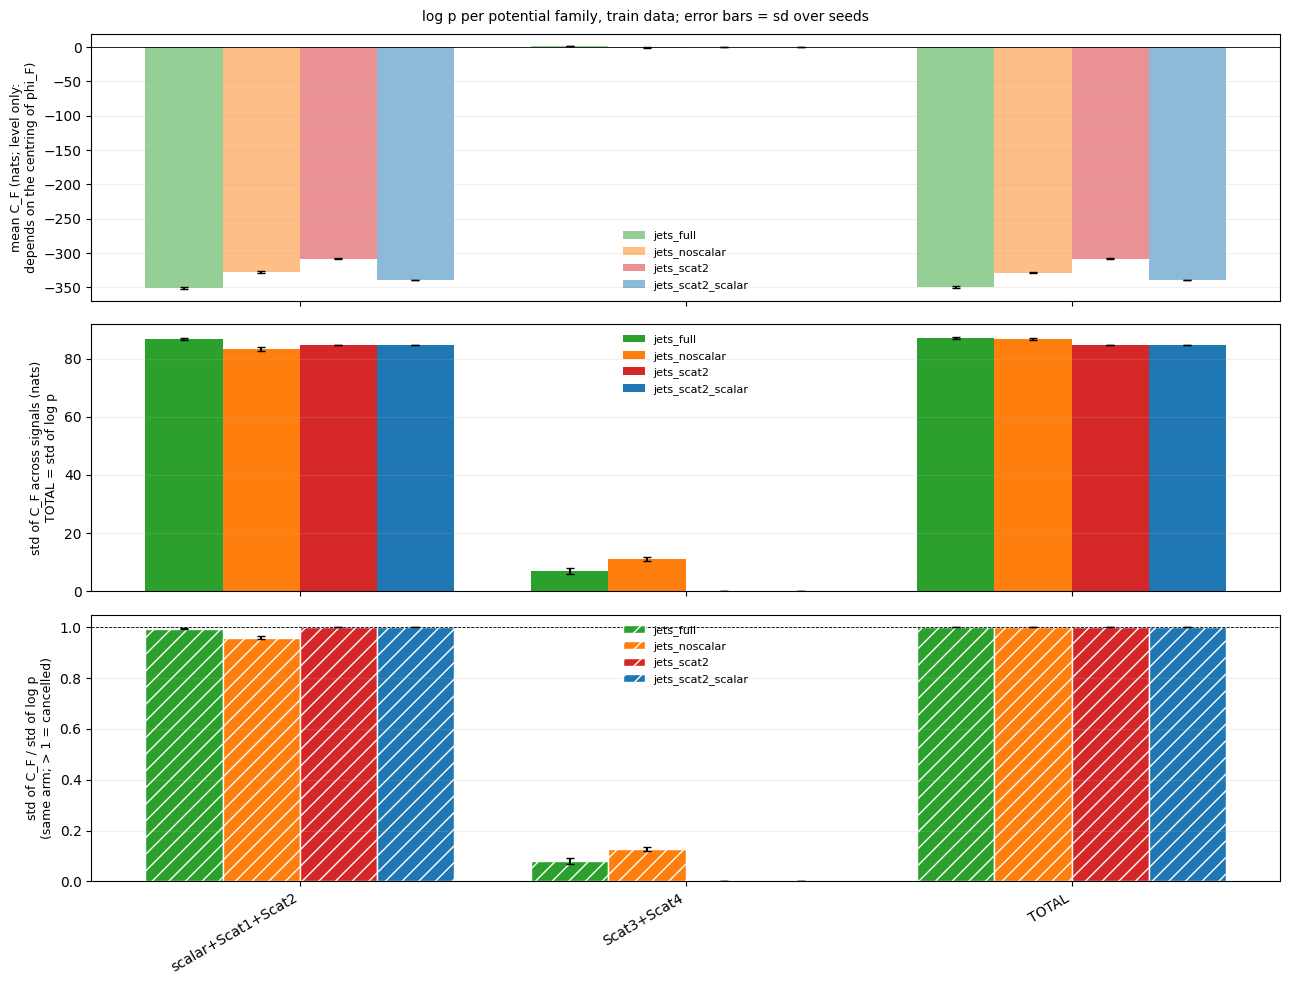

,arm,family,var_share,var_share_sd,corr,std_signals,std_signals_sd
0,jets_full,scalar+Scat1+Scat2,0.992,0.001,0.997,86.8,0.399
1,jets_full,Scat3+Scat4,0.008,0.001,0.105,6.87,1.07
2,jets_full,TOTAL,1,0,1,87.2,0.258
3,jets_noscalar,scalar+Scat1+Scat2,0.952,0.005,0.992,83.3,0.55
4,jets_noscalar,Scat3+Scat4,0.048,0.005,0.375,11.1,0.606
5,jets_noscalar,TOTAL,1,0,1,86.8,0.278
6,jets_scat2,scalar+Scat1+Scat2,1,0,1,84.6,0.049
7,jets_scat2,Scat3+Scat4,0,0,NaN,0,0
8,jets_scat2,TOTAL,1,0,1,84.6,0.049
9,jets_scat2_scalar,scalar+Scat1+Scat2,1,0,1,84.6,0.018


In [24]:
# log p split into two groups: low order (scalar + Scat1 + Scat2) vs high order (Scat3 + Scat4).
# Sum C_F per seed and per signal BEFORE the statistics, so std / corr / seed error bars are those of the group.
HIGH = ('Scat3', 'Scat4')
LOW_NAME, HIGH_NAME = 'scalar+Scat1+Scat2', 'Scat3+Scat4'

def group_runs(runs):
    out = {}
    for arm, r in runs.items():
        fams = r['families'][:-1]                                   # drop TOTAL
        hi = np.array([f.startswith(HIGH) for f in fams])
        print(f'{arm}:\n  {LOW_NAME}: {[f for f, h in zip(fams, hi) if not h]}\n  {HIGH_NAME}: {[f for f, h in zip(fams, hi) if h]}')
        C = {}
        for name, c in r['C'].items():                              # (S, F+1, n), last = TOTAL
            lo_c, hi_c = c[:, :-1][:, ~hi].sum(1), c[:, :-1][:, hi].sum(1)
            C[name] = np.stack([lo_c, hi_c, c[:, -1]], axis=1)
            assert np.allclose(lo_c + hi_c, c[:, -1])
        out[arm] = dict(r, families=[LOW_NAME, HIGH_NAME, 'TOTAL'], C=C)
    return out

runs_g = group_runs(runs)
fig, Tg = lj.plot_family_bars(runs_g); lj.show(fig)
display(Tg[['arm', 'family', 'var_share', 'var_share_sd', 'corr', 'std_signals', 'std_signals_sd']].round(3))